# Phân tích Marketing Campaign Dataset

Notebook đi theo khung 4 giai đoạn:
**Thu thập → Xử lý → Báo cáo → Cảnh báo**




## Cài đặt & import thư viện

In [357]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình hiển thị cho dễ đọc
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("Đã import xong thư viện")


Đã import xong thư viện


## Bước 1: Thu thập dữ liệu (Collect)


In [358]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Đọc dữ liệu vào DataFrame**

In [359]:
import pandas as pd

df = pd.read_csv(
    'drive/MyDrive/Marketing Campaign/marketing_campaign.csv',
    sep='\t'
)

print(f"Số dòng: {df.shape[0]} | Số cột: {df.shape[1]}")
df.head()


Số dòng: 2240 | Số cột: 29


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## Bước 2: Khám phá sơ bộ dữ liệu

In [360]:
# Xem kiểu dữ liệu từng cột
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [361]:
# Kiểm tra giá trị thiếu (missing values) ở từng cột
missing = df.isnull().sum()
missing[missing > 0]


,0
Income,24


In [362]:
# Tiêu chí trùng: giống nhau ở mọi cột, chỉ bỏ ID (ID là khóa định danh, luôn khác nhau)
DEDUP_KEY = [c for c in df.columns if c != 'ID']
dup_mask = df.duplicated(subset=DEDUP_KEY, keep='first')   # True = bản sao sẽ bị loại

print(f"Tổng số dòng trùng lặp thông tin: {dup_mask.sum()} ({dup_mask.mean():.1%} của {len(df)} dòng)")

# 5 dòng trùng đầu tiên (các dòng sẽ bị loại)
df.loc[dup_mask, ['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Dt_Customer', 'MntWines', 'Recency']].head(5)

Tổng số dòng trùng lặp thông tin: 182 (8.1% của 2240 dòng)


,ID,Year_Birth,Education,Marital_Status,Income,Dt_Customer,MntWines,Recency
83,4119,1963,Master,Together,38620.0,11-05-2013,112,56
179,6935,1951,2n Cycle,Married,78497.0,01-12-2013,207,44
281,10144,1976,Graduation,Together,51369.0,25-10-2012,297,84
282,8652,1946,Graduation,Together,37760.0,31-08-2012,84,20
363,933,1978,PhD,Married,37717.0,23-11-2012,9,31


In [363]:
# Loại bản ghi trùng (giữ bản đầu tiên) và lưu lại các dòng bị loại để truy vết
dup_mask = df.duplicated(subset=DEDUP_KEY, keep='first')
df_removed = df[dup_mask].copy()
df_removed.to_csv('removed_duplicates.csv', index=False)
print(f"Loại {dup_mask.sum()} dòng trùng ({dup_mask.mean():.1%}) | còn lại {(~dup_mask).sum()} dòng")
df = df[~dup_mask].copy()


Loại 182 dòng trùng (8.1%) | còn lại 2058 dòng


In [364]:
# Thống kê mô tả nhanh cho các cột số
df.describe()


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2058.000000,2058.000000,2034.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.000000,2058.0,2058.0,2058.000000
mean,5600.764334,1968.787172,52357.791544,0.445578,0.509232,48.951895,303.921769,26.234694,167.704568,37.329446,27.176871,43.873178,2.339164,4.098639,2.660836,5.770651,5.319728,0.073372,0.076774,0.071914,0.065598,0.012634,0.009718,3.0,11.0,0.152089
std,3256.894682,11.973898,25526.956988,0.537556,0.546489,28.999189,336.528217,39.750728,228.303238,54.657215,41.714004,52.126598,1.942947,2.797577,2.933824,3.239113,2.439907,0.260810,0.266297,0.258409,0.247638,0.111714,0.098124,0.0,0.0,0.359195
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2811.750000,1959.000000,35528.250000,0.000000,0.000000,24.000000,23.000000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5515.500000,1970.000000,51533.000000,0.000000,0.000000,49.000000,174.000000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8442.750000,1977.000000,68480.750000,1.000000,1.000000,74.000000,504.000000,33.000000,229.500000,50.000000,33.750000,56.000000,3.000000,6.000000,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


## Bước 3: Xử lý dữ liệu — Phát hiện & xử lý bất thường (Process)

### 3.1 Kiểm tra tuổi bất thường (Year_Birth)


In [365]:
# Xem phân phối năm sinh
print(df['Year_Birth'].describe())

REF_YEAR = 2014   # năm dữ liệu gần nhất trong tập (Dt_Customer lớn nhất thuộc 2014)

# Tuổi > 100 là giá trị sai không rõ nguyên nhân (có thể gõ nhầm, VD 1983 -> 1893)
df['Flag_Age_Invalid'] = (REF_YEAR - df['Year_Birth']) > 100
print(f"Số khách có năm sinh bất thường: {df['Flag_Age_Invalid'].sum()}")
print(df.loc[df['Flag_Age_Invalid'], ['ID', 'Year_Birth']])





count    2058.000000
mean     1968.787172
std        11.973898
min      1893.000000
25%      1959.000000
50%      1970.000000
75%      1977.000000
max      1996.000000
Name: Year_Birth, dtype: float64
Số khách có năm sinh bất thường: 3
        ID  Year_Birth
192   7829        1900
239  11004        1893
339   1150        1899


In [366]:
# Loại bỏ các dòng có tuổi bất thường
df = df.loc[~df['Flag_Age_Invalid']].copy()
df.drop(columns='Flag_Age_Invalid', inplace=True)

# Kiểm tra lại sau xử lý
print("\n--- Sau khi loại bỏ tuổi bất thường ---")
print(f"Số dòng còn lại: {len(df)}")
print(df['Year_Birth'].describe())
print(f"Số khách còn tuổi > 100: {((REF_YEAR - df['Year_Birth']) > 100).sum()}")


--- Sau khi loại bỏ tuổi bất thường ---
Số dòng còn lại: 2055
count    2055.000000
mean     1968.891484
std        11.666261
min      1940.000000
25%      1959.000000
50%      1970.000000
75%      1977.000000
max      1996.000000
Name: Year_Birth, dtype: float64
Số khách còn tuổi > 100: 0


Phát hiện 3 khách hàng có độ tuổi bất thường trên 100 tuổi. Sau khi kiểm tra, các giá trị này không cho thấy mối liên hệ rõ ràng với các thuộc tính khác trong bộ dữ liệu và có thể là dữ liệu nhập sai. Do số lượng bản ghi bất thường nhỏ, tiến hành loại bỏ 3 dòng dữ liệu này để hạn chế ảnh hưởng đến kết quả phân tích. Sau khi xử lý, kiểm tra lại dữ liệu để đảm bảo không còn khách hàng có độ tuổi vượt quá 100 tuổi.


### 3.2 Kiểm tra thu nhập bất thường (Income)

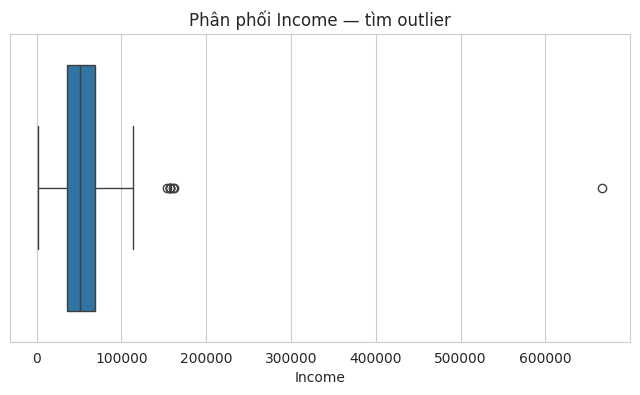

In [367]:
# Vẽ boxplot để nhìn outlier trực quan
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Income'])
plt.title('Phân phối Income — tìm outlier')
plt.show()


In [368]:
# Xem các giá trị Income cao bất thường
print(df[df['Income'] > 150000][['ID', 'Income']])

# Chỉ GẮN CỜ, không sửa giá trị: thu nhập khác nhau là bình thường,
# chưa đủ căn cứ để coi 666,666 là sai -> giữ nguyên, phân tích sâu sau.
df['Flag_Income_Missing'] = df['Income'].isnull()     # vốn dĩ bị thiếu
df['Flag_Income_Outlier'] = df['Income'] > 200000     # cần xem xét: cách xa phần còn lại ~4 lần

print(f"Income thiếu: {df['Flag_Income_Missing'].sum()} | Income cần xem xét (>200,000): {df['Flag_Income_Outlier'].sum()}")
print(df.loc[df['Flag_Income_Outlier'], ['ID', 'Income']])

# Income thiếu giữ NaN, không gán median
print()
print(f"Income để trống: {df['Income'].isnull().sum()} | Số dòng giữ nguyên: {len(df)}")


         ID    Income
164    8475  157243.0
617    1503  162397.0
655    5555  153924.0
687    1501  160803.0
1300   5336  157733.0
1653   4931  157146.0
2132  11181  156924.0
2233   9432  666666.0
Income thiếu: 24 | Income cần xem xét (>200,000): 1
        ID    Income
2233  9432  666666.0

Income để trống: 24 | Số dòng giữ nguyên: 2055


- Income = thu nhập HỘ GIA ĐÌNH hàng năm (theo mô tả nguồn) -> giá trị cao không phải bất khả thi.

- Cờ này chỉ đánh dấu 666,666: cao gấp \~4 lần giá trị kế tiếp (~162k) và là giá trị lặp chữ số.

- Tài liệu nguồn không ghi nhận đây là mã mặc định/test; chưa xác minh được -> chỉ gắn cờ, giữ nguyên giá trị và KPI dùng median, correlation báo cả hai bản.

- Lý do không gán median: không có căn cứ, tránh làm méo phân phối.


### 3.3 Chuẩn hóa cột phân loại (Marital_Status)

In [369]:
print(df['Marital_Status'].value_counts())


Marital_Status
Married     795
Together    520
Single      447
Divorced    215
Widow        71
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


In [370]:
# Gộp các giá trị rác/lạ về nhóm hợp lý
df['Marital_Status'] = df['Marital_Status'].replace({
    'Alone': 'Single',
    'YOLO': 'Single',
    'Absurd': 'Single'
})
print(df['Marital_Status'].value_counts())


Marital_Status
Married     795
Together    520
Single      454
Divorced    215
Widow        71
Name: count, dtype: int64


**Chuẩn hóa `Marital_Status`:** 7 dòng có giá trị lạ (`Alone` 3, `YOLO` 2, `Absurd` 2) được gộp vào `Single`.

- `Alone` có nghĩa tương đương `Single`, nên việc gộp hợp lý.
- `YOLO` và `Absurd` là giá trị nhập bừa, không có căn cứ xác định tình trạng hôn nhân. Việc gộp vào `Single` là **giả định**.
- Tác động nhỏ: 7/2055 dòng (~0.3%), nhóm `Single` tăng từ 447 lên 454.

### 3.4 Loại bỏ cột không mang thông tin

In [371]:
# Z_CostContact và Z_Revenue chỉ có 1 giá trị duy nhất toàn bộ dataset -> không có ý nghĩa phân tích
print(df['Z_CostContact'].nunique(), df['Z_Revenue'].nunique())

df = df.drop(columns=['Z_CostContact', 'Z_Revenue'])


1 1


## Bước 4: Tạo thêm cột tính toán (Feature Engineering)




In [372]:
# Tuổi hiện tại của khách hàng (tính theo năm dữ liệu gần nhất trong tập là 2014)
df['Age'] = 2014 - df['Year_Birth']

# Tổng chi tiêu trên tất cả nhóm sản phẩm
mnt_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['TotalSpend'] = df[mnt_cols].sum(axis=1)

# Tổng số lần mua hàng qua tất cả kênh
purchase_cols = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df['TotalPurchases'] = df[purchase_cols].sum(axis=1)

# Tổng số con (trẻ em + tuổi teen) trong nhà
df['TotalChildren'] = df['Kidhome'] + df['Teenhome']

# Chuyển ngày gia nhập thành kiểu datetime, tính số ngày là khách hàng (tenure)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
df['Customer_Tenure_Days'] = (df['Dt_Customer'].max() - df['Dt_Customer']).dt.days

df[['Age', 'TotalSpend', 'TotalPurchases', 'TotalChildren', 'Customer_Tenure_Days']].head()


,Age,TotalSpend,TotalPurchases,TotalChildren,Customer_Tenure_Days
0,57,1617,22,0,663
1,60,27,4,2,113
2,49,776,20,0,312
3,30,53,6,1,139
4,33,422,14,1,161


### Flag bất nhất mua hàng

In [373]:
# Dòng bất nhất mua hàng: có chi tiêu nhưng không có lượt mua nào qua 3 kênh,
# hoặc số lần mua giảm giá lớn hơn tổng số lần mua qua 3 kênh
channel_total = df[purchase_cols].sum(axis=1)
df['Flag_Purchase_Inconsistent'] = (
    ((channel_total == 0) & (df['TotalSpend'] > 0)) |
    (df['NumDealsPurchases'] > channel_total)
)
print(f"Dòng bất nhất mua hàng: {df['Flag_Purchase_Inconsistent'].sum()} (giữ lại, chỉ gắn cờ)")
print(df.loc[df['Flag_Purchase_Inconsistent'], ['ID', 'TotalSpend', 'NumDealsPurchases'] + purchase_cols])

Dòng bất nhất mua hàng: 7 (giữ lại, chỉ gắn cờ)
         ID  TotalSpend  NumDealsPurchases  NumWebPurchases  \
655    5555           6                  0                0   
981    3955           6                  0                0   
1042  10749         178                 15                0   
1245   6862           8                 15                0   
1524  11110           5                  0                0   
1846   9931           9                 15                0   
2132  11181           8                  0                0   

      NumCatalogPurchases  NumStorePurchases  
655                     0                  0  
981                     0                  0  
1042                    1                  0  
1245                    0                  0  
1524                    0                  0  
1846                    0                  0  
2132                    0                  0  


## Bước 5: Báo cáo — Phân tích tổng quan (Report)

### 5.1 Các chỉ số KPI chính


In [374]:
print(f"Tổng số khách hàng          : {len(df)}")
print(f"Chi tiêu trung bình/khách    : {df['TotalSpend'].mean():.0f}")
print(f"Thu nhập trung bình          : {df['Income'].mean():.0f}")
print(f"Tỷ lệ phản hồi campaign mới  : {df['Response'].mean()*100:.1f}%")
print(f"Tỷ lệ khiếu nại              : {df['Complain'].mean()*100:.2f}%")


Tổng số khách hàng          : 2055
Chi tiêu trung bình/khách    : 606
Thu nhập trung bình          : 52346
Tỷ lệ phản hồi campaign mới  : 15.2%
Tỷ lệ khiếu nại              : 0.92%


### 5.2 Tỷ lệ chấp nhận từng đợt campaign trước đó

In [375]:
campaign_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']

acceptance_table = pd.DataFrame({
    'Accepted_Count': df[campaign_cols].sum(),
    'Acceptance_Rate_%': (df[campaign_cols].mean() * 100).round(1)
})
acceptance_table


,Accepted_Count,Acceptance_Rate_%
AcceptedCmp1,135,6.6
AcceptedCmp2,26,1.3
AcceptedCmp3,151,7.3
AcceptedCmp4,158,7.7
AcceptedCmp5,147,7.2
Response,313,15.2


### 5.3 Tương quan giữa Income và TotalSpend

In [376]:
# Pearson: toàn bộ dữ liệu vs bỏ outlier Income (Flag_Income_Outlier)
df_no_out = df[~df['Flag_Income_Outlier']]

corr_all    = df[['Income', 'TotalSpend']].corr().iloc[0, 1]
corr_no_out = df_no_out[['Income', 'TotalSpend']].corr().iloc[0, 1]

print(f"Pearson (toàn bộ, n={df[['Income','TotalSpend']].dropna().shape[0]})      : {corr_all:.2f}")
print(f"Pearson (bỏ outlier, n={df_no_out[['Income','TotalSpend']].dropna().shape[0]})   : {corr_no_out:.2f}")

Pearson (toàn bộ, n=2031)      : 0.65
Pearson (bỏ outlier, n=2030)   : 0.79


In [377]:
corr_spearman = df[['Income', 'TotalSpend']].corr(method='spearman').iloc[0, 1]
print(f"Spearman (toàn bộ)                  : {corr_spearman:.2f}")

Spearman (toàn bộ)                  : 0.85


Một điểm 666,666 làm Pearson thấp đi, còn Spearman dựa trên thứ hạng nên ít bị ảnh hưởng.

Kết luận: Income và chi tiêu có quan hệ cùng chiều mạnh.

## Bước 6: Trực quan hóa

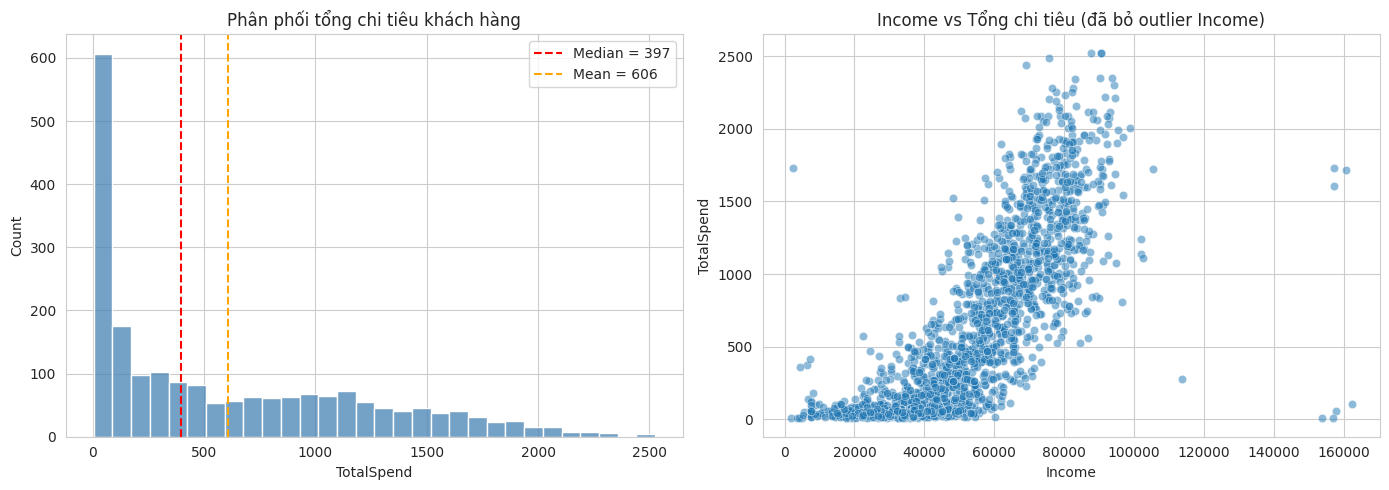

In [378]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Phân phối tổng chi tiêu (lệch phải -> dùng median thay vì mean)
sns.histplot(df['TotalSpend'], bins=30, ax=axes[0], color='steelblue')
axes[0].axvline(df['TotalSpend'].median(), color='red', linestyle='--',
                label=f"Median = {df['TotalSpend'].median():.0f}")
axes[0].axvline(df['TotalSpend'].mean(), color='orange', linestyle='--',
                label=f"Mean = {df['TotalSpend'].mean():.0f}")
axes[0].set_title('Phân phối tổng chi tiêu khách hàng')
axes[0].legend()

# 2. Income vs TotalSpend (bỏ outlier 666,666 để không nén trục)
df_plot = df[~df['Flag_Income_Outlier']]
sns.scatterplot(data=df_plot, x='Income', y='TotalSpend', ax=axes[1], alpha=0.5)
axes[1].set_title('Income vs Tổng chi tiêu (đã bỏ outlier Income)')

plt.tight_layout()
plt.show()

- **Chi tiêu lệch phải:** median (397) thấp hơn nhiều so với mean (606), nên dùng median làm KPI. Khoảng 30% khách chi rất ít, phần còn lại chi đều ở mức trung bình đến cao.
- **Income và chi tiêu cùng chiều, mạnh nhưng không tuyến tính:** chi tiêu tăng nhanh từ ~50k thu nhập trở lên và phân tán rộng ở nhóm thu nhập cao, nên thu nhập chưa giải thích hết hành vi chi tiêu.
- Một số điểm bất thường được giữ lại và gắn cờ, chưa đủ căn cứ để coi là lỗi.

## Bước 7: Cảnh báo — Hàm phát hiện bất thường tự động (Alert)

Hàm này mô phỏng logic cảnh báo — trong thực tế có thể chạy hàm này định kỳ mỗi khi có dữ liệu mới, và cho nó gửi email/Slack thay vì chỉ in ra màn hình.


In [379]:
def check_anomalies(data):
    alerts = []

    # Canh bao thu nhap bat thuong
    income_issue = data[data['Income'] > 200000]
    if len(income_issue) > 0:
        alerts.append(f"{len(income_issue)} khách hàng có Income > 200,000 (cần xác minh)")

    # Canh bao dong bat nhat mua hang: co chi tieu nhung khong co luot mua nao qua 3 kenh,
    # hoac so lan mua giam gia lon hon tong so lan mua qua 3 kenh
    channel_total = data[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(axis=1)
    purchase_issue = data[
        ((channel_total == 0) & (data['TotalSpend'] > 0)) |
        (data['NumDealsPurchases'] > channel_total)
    ]
    if len(purchase_issue) > 0:
        alerts.append(f"{len(purchase_issue)} dòng có số lần mua không khớp với chi tiêu hoặc số lần mua giảm giá (ID: {purchase_issue['ID'].tolist()})")

    # Canh bao ty le phan hoi campaign qua thap
    response_rate = data['Response'].mean()
    if response_rate < 0.05:
        alerts.append(f"Tỷ lệ phản hồi campaign quá thấp: {response_rate*100:.1f}%")

    # Canh bao gia tri phan loai la
    valid_marital = ['Married', 'Together', 'Single', 'Divorced', 'Widow']
    invalid_marital = data[~data['Marital_Status'].isin(valid_marital)]
    if len(invalid_marital) > 0:
        alerts.append(f"{len(invalid_marital)} dòng có Marital_Status không hợp lệ")

    if alerts:
        print("PHÁT HIỆN CẢNH BÁO:")
        for a in alerts:
            print(" -", a)
    else:
        print("Không phát hiện bất thường nào trong lần kiểm tra này.")

    return alerts

check_anomalies(df)


PHÁT HIỆN CẢNH BÁO:
 - 1 khách hàng có Income > 200,000 (cần xác minh)
 - 7 dòng có số lần mua không khớp với chi tiêu hoặc số lần mua giảm giá (ID: [5555, 3955, 10749, 6862, 11110, 9931, 11181])


['1 khách hàng có Income > 200,000 (cần xác minh)',
 '7 dòng có số lần mua không khớp với chi tiêu hoặc số lần mua giảm giá (ID: [5555, 3955, 10749, 6862, 11110, 9931, 11181])']

## Bước 8: Xuất dữ liệu đã làm sạch

In [380]:
OUT_FILE = 'marketing_campaign_cleaned.csv'

# Flag_* sang 0/1 trên bản xuất, df gốc giữ nguyên kiểu bool
flag_cols = df.filter(regex='^Flag_').columns
df.astype({c: int for c in flag_cols}).to_csv(OUT_FILE, index=False)
print(f"Đã lưu file {OUT_FILE} ({len(df)} dòng, {df.shape[1]} cột)")

# files.download chỉ có trên Colab
try:
    from google.colab import files
    files.download(OUT_FILE)
except ImportError:
    print("Không chạy trên Colab: bỏ qua bước tải file.")


Đã lưu file marketing_campaign_cleaned.csv (2055 dòng, 35 cột)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>